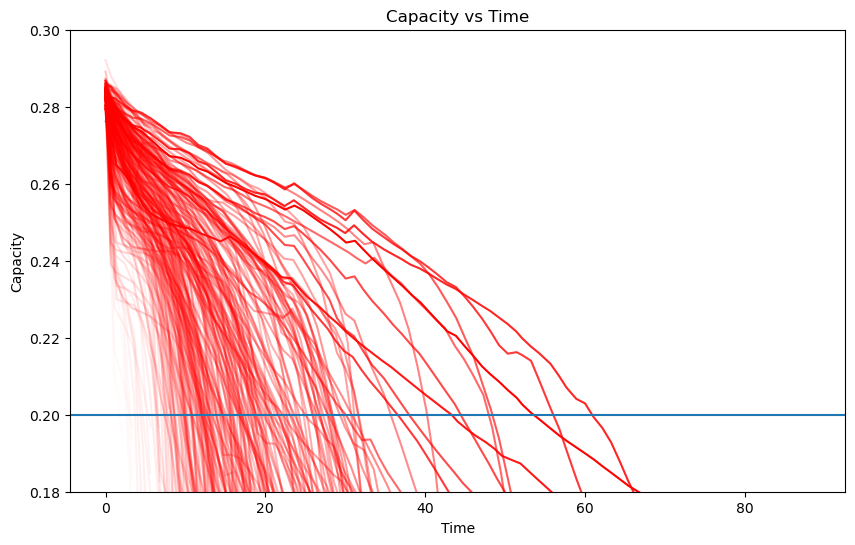

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

folder = Path('C:/Users/sures/Documents/DA Projects/IowaStateCells/capacity_fade/Release 1.0')

files = list(folder.glob("*.csv"))

lifetimes = []

for file in files:
    df = pd.read_csv(file)
    lifetimes.append(df["Time"].max())

norm = plt.Normalize((min(lifetimes)), max(lifetimes))


plt.figure(figsize=(10, 6))

for file, lifetime in zip(files, lifetimes):
    df = pd.read_csv(file)

    plt.plot(
        df["Time"],
        df["Capacity"],
        color='red',
        alpha=norm((lifetime))
    )


plt.axhline((0.25*0.80))
plt.xlabel("Time")
plt.ylabel("Capacity")
plt.title("Capacity vs Time")
plt.ylim(0.18, 0.3)
plt.show()

In [42]:
from pathlib import Path
groupData = pd.DataFrame({
    'ID' : pd.Series(dtype = str),
    'Lifetime' : pd.Series(dtype = float)
})
outList = []  
for file in files:
    fileName = Path(file).stem
    df = pd.read_csv(file)
    df = df[df['Capacity'] > 0.20]
    lifetime = max(df['Time'])
    outDict = {'ID' : fileName, 'Lifetime' : lifetime}

    outList.append(outDict)

groupData = pd.concat([groupData, pd.DataFrame(outList)], ignore_index=True)

    
    
    

In [43]:
groupData

,ID,Lifetime
0,G10C1,14.804795
1,G10C2,19.724325
2,G10C3,13.742006
3,G10C4,24.420413
4,G11C1,1.120349
...,...,...
233,G8C4,20.737884
234,G9C1,5.508981
235,G9C2,5.560398
236,G9C3,7.888839
